# Etapa 2: Protocolo de validação

**Objetivo:** definir **como** vamos medir o desempenho dos modelos. Esse procedimento vale para o projeto inteiro: todo modelo das Etapas 3 e 4 é comparado com ele.

Esta é a etapa que mais pesa na nota. O enunciado diz que o relatório será avaliado pela **qualidade da validação**.

**O problema central.** O que nos interessa é o erro **fora da amostra**, $E_{out}$: o erro em pares (usuário, filme) que o modelo nunca viu, como os 2000 do teste. Só que esse erro não pode ser observado diretamente. O que conseguimos calcular é o erro **dentro da amostra**, $E_{in}$, nos dados usados para ajustar o modelo. A pergunta deste notebook é como estimar $E_{out}$ de forma confiável usando só o `train.csv`.

**Roteiro**
1. Por que $E_{in}$ não serve
2. Separar uma parte para validação (holdout) e o problema de usar uma única divisão
3. Validação cruzada k-fold repetida: o protocolo escolhido
4. Os baselines medidos com o protocolo
5. Como comparar dois modelos: a comparação pareada
6. Escolher hiperparâmetros sem se enganar: a curva viés–variância e a validação aninhada
7. Regras do protocolo

In [1]:
import sys, warnings
sys.path.insert(0, "..")  # permite importar o pacote src/ a partir da pasta notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.tree import DecisionTreeRegressor

from src.data import load_train
from src.features import raw_features, raw_plus_affinity
from src.validation import (N_REPEATS, N_SPLITS, SEED, compare, cross_validate,
                            make_folds, paired_difference, rmse)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.precision", 4)
# O BLAS do macOS emite avisos espúrios de overflow no produto matricial; os resultados não são afetados.
warnings.filterwarnings("ignore", category=RuntimeWarning, module="sklearn")

X, y = load_train()
print(X.shape, y.shape)

(4000, 10) (4000,)


### Sobre o código compartilhado em `src/`

A partir daqui, o código que será reutilizado fica em módulos Python na pasta `src/`. Assim **todos os notebooks usam exatamente o mesmo procedimento**.

| Módulo | Conteúdo |
|---|---|
| `src/data.py` | `load_train()` e `load_test()` |
| `src/features.py` | funções que constroem atributos: `raw_features` (os 10 brutos), `raw_plus_affinity` |
| `src/validation.py` | o protocolo: `make_folds`, `cross_validate`, `compare`, `paired_difference`, `rmse` |

Os modelos são montados como **Pipelines**: primeiro a construção de atributos, depois o estimador. Essa organização não é só estética. É ela que garante que tudo o que "aprende" com os dados seja reajustado **dentro** de cada dobra, como veremos na seção 7.

In [2]:
linear_bruta = make_pipeline(FunctionTransformer(raw_features), LinearRegression())
linear_bruta

Pipeline(steps=[('functiontransformer',
                 FunctionTransformer(func=<function raw_features at 0x12e460430>)),
                ('linearregression', LinearRegression())])

## 1. Por que o erro de treino ($E_{in}$) não serve

Um modelo suficientemente flexível consegue **decorar** o treino. O exemplo extremo é uma árvore de decisão sem limite de profundidade: ela cria uma folha para cada observação e obtém $E_{in} = 0$. Isso não significa que ela vá prever bem dados novos.

In [3]:
arvore = make_pipeline(FunctionTransformer(raw_features), DecisionTreeRegressor(random_state=0))

X_tr, X_va, y_tr, y_va = train_test_split(X, y, test_size=0.2, random_state=0)
for nome, m in [("linear bruta", linear_bruta), ("árvore sem limite", arvore)]:
    m = clone(m).fit(X_tr, y_tr)
    print(f"{nome:18s}  E_in = {rmse(y_tr, m.predict(X_tr)):.3f}   erro em dados não vistos = {rmse(y_va, m.predict(X_va)):.3f}")

linear bruta        E_in = 0.813   erro em dados não vistos = 0.853
árvore sem limite   E_in = 0.000   erro em dados não vistos = 1.001


**Leitura:** a árvore tem erro de treino **zero**, mas nos dados não vistos é muito pior do que a regressão linear e não fica longe de simplesmente prever a média (≈ 1,17). É o **sobreajuste** (*overfitting*): o modelo ajustou o ruído do treino.

Na regressão linear, $E_{in}$ e o erro de validação são parecidos. Com poucos parâmetros (≈ 10) e 3200 observações, a teoria da generalização garante que $E_{in}$ e $E_{out}$ ficam próximos. Para a árvore sem limite, cuja complexidade (dimensão VC) é enorme, essa garantia desaparece.

**Conclusão:** precisamos avaliar o modelo em dados que ele **não usou** para se ajustar.

## 2. Holdout: separar uma parte para validação

A ideia mais simples é separar, por exemplo, 20% do treino (800 linhas), ajustar nos 80% restantes e medir o erro nesses 800.

**Por que funciona?** Para um modelo **fixo**, o erro nos 800 pontos de validação é uma média de 800 perdas independentes. Pela lei dos grandes números, e quantitativamente pela **desigualdade de Hoeffding**, essa média fica perto do valor esperado, que é o $E_{out}$ do modelo. O modelo não foi escolhido olhando esses pontos, então não há o problema de "muitas hipóteses" que afeta o $E_{in}$.

**O problema:** com 800 pontos ainda há bastante variabilidade. Vamos repetir o holdout com 200 sementes diferentes, para o **mesmo** modelo (linear bruta), e ver quanto o resultado muda só por causa da sorte da divisão.

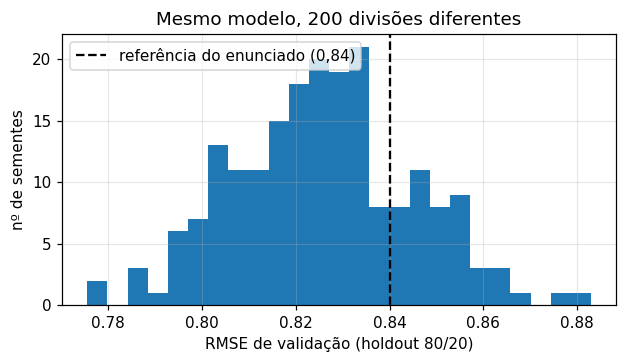

média 0.826 | desvio 0.019 | mín 0.776 | máx 0.883


In [4]:
holdout = []
for s in range(200):
    X_tr, X_va, y_tr, y_va = train_test_split(X, y, test_size=0.2, random_state=s)
    holdout.append(rmse(y_va, clone(linear_bruta).fit(X_tr, y_tr).predict(X_va)))
holdout = np.array(holdout)

fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.hist(holdout, bins=25, color="C0")
ax.axvline(0.84, color="k", ls="--", label="referência do enunciado (0,84)")
ax.set(xlabel="RMSE de validação (holdout 80/20)", ylabel="nº de sementes",
       title="Mesmo modelo, 200 divisões diferentes")
ax.legend()
plt.show()
print(f"média {holdout.mean():.3f} | desvio {holdout.std():.3f} | mín {holdout.min():.3f} | máx {holdout.max():.3f}")

**Leitura:** dependendo só da divisão, o **mesmo modelo** pode parecer ter RMSE de ≈ 0,78 ou ≈ 0,88. Diferenças entre modelos de alguns centésimos, que são justamente as que vamos querer detectar, ficariam escondidas nesse ruído. Um holdout único não basta.

## 3. Validação cruzada k-fold repetida

**k-fold:** dividimos os dados em $k$ partes (dobras). Ajustamos o modelo $k$ vezes, cada vez deixando uma dobra de fora para validação. O resultado é a média dos $k$ erros. Assim **todas** as 4000 linhas são usadas para validar uma vez, e a variabilidade cai.

**Repetida:** fazemos o k-fold várias vezes, com partições diferentes, e tiramos a média. Isso reduz ainda mais a dependência da sorte da partição.

### Qual $k$?
- $k$ pequeno (por exemplo, 2): cada modelo é treinado com só metade dos dados. A estimativa tende a ser **pessimista** (viesada para cima), porque o modelo final será treinado com 4000 linhas.
- $k$ grande (por exemplo, 20): treinos quase do tamanho total, logo pouco viés, mas o custo computacional é maior.
- $k = 5$ ou $10$ é o compromisso usual (ISLR, seção 5.1.4).

Vamos medir, para a linear bruta, a média e a variabilidade da estimativa conforme $k$ (20 partições diferentes para cada $k$).

In [5]:
linhas = []
for k in [2, 5, 10, 20]:
    est = [cross_validate(linear_bruta, X, y, folds=make_folds(len(y), n_splits=k, n_repeats=1, seed=s)).mean
           for s in range(20)]
    linhas.append({"k": k, "estimativa média": np.mean(est), "variação entre partições (desvio)": np.std(est)})
pd.DataFrame(linhas).set_index("k")

,estimativa média,variação entre partições (desvio)
k,,
2,0.8244,0.0022
5,0.8233,0.0005
10,0.8228,0.0004
20,0.8221,0.0004


**Leitura**
- Com $k = 2$, a estimativa é ligeiramente maior (mais pessimista), como esperado. A partir de $k = 5$ quase não muda.
- A variação entre partições é **muito** menor do que a do holdout (≈ 0,0005 contra ≈ 0,019).

### O protocolo escolhido

> **Validação cruzada com 5 dobras, repetida 3 vezes (15 ajustes por modelo), semente fixa 2026.**
> **As mesmas 15 partições são usadas para todos os modelos.**

O RMSE é calculado com as previsões **cortadas em [0, 5]**, como na pontuação oficial. Reportamos a média das 15 dobras e o desvio entre elas.

In [6]:
folds = make_folds(len(y))  # 5 dobras x 3 repetições, semente 2026 (definidas em src/validation.py)
print(f"{len(folds)} partições; treino com {len(folds[0][0])} linhas, validação com {len(folds[0][1])} linhas")

# a variação da estimativa final quando trocamos a semente do protocolo
est = [cross_validate(linear_bruta, X, y, folds=make_folds(len(y), seed=s)).mean for s in range(30)]
print(f"linear bruta, 30 sementes do protocolo: média {np.mean(est):.4f}, desvio {np.std(est):.4f}")

15 partições; treino com 3200 linhas, validação com 800 linhas


linear bruta, 30 sementes do protocolo: média 0.8232, desvio 0.0003


Trocar a semente do protocolo muda a estimativa só na **quarta casa decimal**. O protocolo é estável.

## 4. Os baselines medidos com o protocolo

Primeira checagem de sanidade: o protocolo deve reproduzir os valores de referência do enunciado (constante ≈ 1,19 e linear bruta ≈ 0,84). Incluímos também a linear com a afinidade (achado da EDA) e a árvore sem limite.

In [7]:
linear_afinidade = make_pipeline(FunctionTransformer(raw_plus_affinity), LinearRegression())

res_const = cross_validate(DummyRegressor(strategy="mean"), X, y, "constante (média)", folds)
res_lin = cross_validate(linear_bruta, X, y, "linear bruta", folds)
res_aff = cross_validate(linear_afinidade, X, y, "linear + afinidade", folds)
res_tree = cross_validate(arvore, X, y, "árvore sem limite", folds)

tabela = compare([res_const, res_lin, res_aff, res_tree])
tabela

,RMSE validação,desvio entre dobras,RMSE treino (E_in)
modelo,,,
linear + afinidade,0.6490,0.0147,0.6458
linear bruta,0.8243,0.0202,0.8203
árvore sem limite,1.0328,0.0356,0.0000
constante (média),1.1657,0.0252,1.1654


**Leitura**
- **Constante ≈ 1,17 e linear bruta ≈ 0,82:** reproduzem as referências do enunciado (1,19 e 0,84). A pequena diferença é esperada: o conjunto de teste é outra amostra da mesma distribuição. O protocolo está funcionando.
- **Linear + afinidade ≈ 0,65:** um ganho grande e consistente (ver seção 5).
- **Árvore sem limite:** $E_{in} = 0$ e validação ≈ 1,03. É o retrato do sobreajuste.
- **A coluna $E_{in}$:** nos modelos lineares, treino e validação quase coincidem (baixa variância). Nos modelos flexíveis, a **distância** entre os dois é o sintoma de sobreajuste a vigiar.

## 5. Comparar modelos: a comparação pareada

"0,649 é menor que 0,824", mas a diferença é real ou é sorte da partição? Como **os dois modelos foram avaliados nas mesmas 15 partições**, podemos olhar a diferença **dobra a dobra**. A dificuldade de cada dobra (algumas têm pares mais difíceis de prever) afeta os dois modelos e se cancela na diferença.

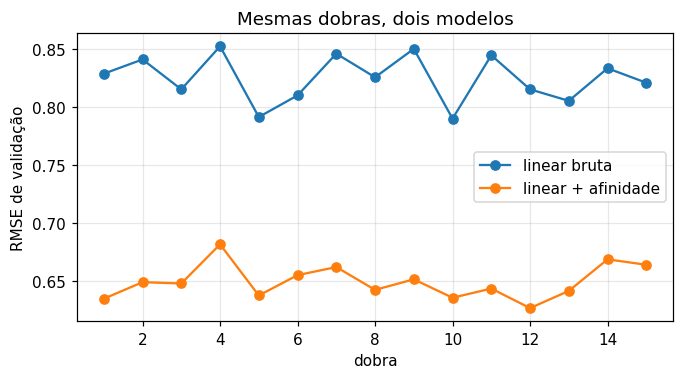

diferença média (afinidade - bruta) = -0.1753  |  erro padrão aproximado = 0.0044
a linear + afinidade é melhor em 15 de 15 dobras


In [8]:
fig, ax = plt.subplots(figsize=(7, 3.4))
idx = np.arange(1, len(folds) + 1)
ax.plot(idx, res_lin.val_scores, "o-", label="linear bruta")
ax.plot(idx, res_aff.val_scores, "o-", label="linear + afinidade")
ax.set(xlabel="dobra", ylabel="RMSE de validação", title="Mesmas dobras, dois modelos")
ax.legend()
plt.show()

d, se = paired_difference(res_aff, res_lin)
print(f"diferença média (afinidade - bruta) = {d:.4f}  |  erro padrão aproximado = {se:.4f}")
print(f"a linear + afinidade é melhor em {np.sum(res_aff.val_scores < res_lin.val_scores)} de {len(folds)} dobras")

**Leitura:** as duas curvas sobem e descem juntas (há dobras "difíceis" e "fáceis"), mas a afinidade é melhor em **todas** as dobras. A diferença média é cerca de 40 vezes o seu erro padrão. Não há dúvida de que o ganho é real.

**Regra prática para o projeto:** ao dizer que um modelo é melhor que outro, reportar a diferença pareada e o seu erro padrão. Se a diferença for menor que uns 2 erros padrão, os modelos são **empatados**, e preferimos o mais simples (Navalha de Ockham).

> **Cuidado:** esse erro padrão é aproximado. As dobras compartilham dados de treino e não são independentes, de modo que o erro padrão tende a ser subestimado. Por isso a regra dos 2 erros padrão é uma heurística, não um teste formal.

## 6. Escolher hiperparâmetros sem se enganar

Muitos modelos têm **hiperparâmetros**: o $k$ do kNN, a penalização do Ridge, a profundidade de uma árvore. Eles controlam a **complexidade** do modelo e precisam ser escolhidos pela validação.

### 6.1 A curva viés–variância na prática

O kNN é um bom exemplo. Com $k = 1$, a previsão é a nota do vizinho mais próximo, o que dá um modelo muito flexível, com **variância alta**. Com $k$ grande, a previsão é a média de muitos vizinhos, o que dá um modelo muito rígido, com **viés alto**.

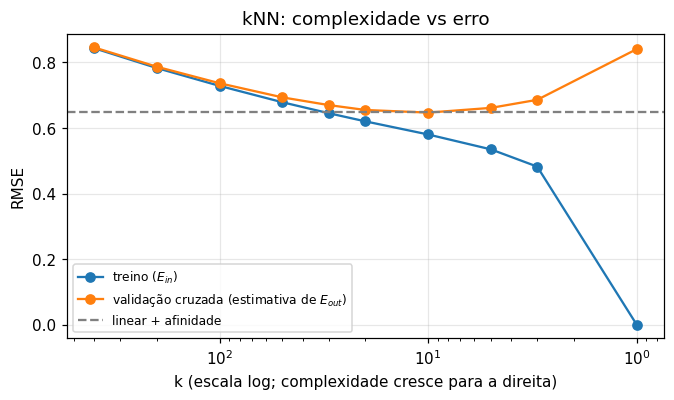

melhor: kNN k=10 com RMSE de validação 0.6470


In [9]:
def knn(k):
    return make_pipeline(FunctionTransformer(raw_plus_affinity), StandardScaler(), KNeighborsRegressor(n_neighbors=k))

ks = [1, 3, 5, 10, 20, 30, 50, 100, 200, 400]
res_knn = [cross_validate(knn(k), X, y, f"kNN k={k}", folds) for k in ks]

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(ks, [r.train_scores.mean() for r in res_knn], "o-", label="treino ($E_{in}$)")
ax.plot(ks, [r.mean for r in res_knn], "o-", label="validação cruzada (estimativa de $E_{out}$)")
ax.axhline(res_aff.mean, color="gray", ls="--", label="linear + afinidade")
ax.set_xscale("log")
ax.invert_xaxis()  # da esquerda para a direita, o modelo fica mais complexo (k menor)
ax.set(xlabel="k (escala log; complexidade cresce para a direita)", ylabel="RMSE",
       title="kNN: complexidade vs erro")
ax.legend(fontsize=8)
plt.show()

melhor = min(res_knn, key=lambda r: r.mean)
print(f"melhor: {melhor.name} com RMSE de validação {melhor.mean:.4f}")

**Leitura:** é a figura clássica do curso.
- **À esquerda ($k$ grande, modelo simples):** treino e validação são altos e próximos. Domina o **viés**.
- **À direita ($k$ pequeno, modelo complexo):** o erro de treino cai até zero, mas o de validação volta a subir. Domina a **variância**, ou seja, o sobreajuste.
- **No meio**, o ponto ótimo equilibra os dois.

### 6.2 O otimismo da seleção e a validação aninhada

Há uma sutileza. Ao testar 10 valores de $k$ e **escolher o melhor pelo erro de validação**, essa validação deixa de ser "dados que o modelo não viu": ela foi usada para escolher. O menor dos 10 erros tende a ser **otimista**. É o mesmo argumento da desigualdade de Hoeffding com $M$ hipóteses: a garantia piora quando escolhemos entre muitas opções (fator $M$ na *union bound*).

Para estimar honestamente o erro do **procedimento completo** ("kNN com $k$ escolhido por validação cruzada"), usamos a **validação cruzada aninhada**:
- O **laço externo** são as nossas 15 partições de sempre.
- Em cada partição, o **laço interno** escolhe $k$ por validação cruzada usando **somente** a parte de treino.
- O $k$ escolhido é avaliado na dobra externa, que não participou da escolha.

No scikit-learn isso é natural: colocamos um `GridSearchCV` (o laço interno) **dentro** do `cross_validate` (o laço externo).

In [10]:
busca = GridSearchCV(
    knn(20),
    {"kneighborsregressor__n_neighbors": ks},
    cv=KFold(5, shuffle=True, random_state=0),
    scoring="neg_root_mean_squared_error",
)
# Laço externo escrito à mão, para vermos qual k o laço interno escolhe em cada partição
y_arr = np.asarray(y)
erros_externos, k_escolhidos = [], []
for tr, va in folds:
    b = clone(busca).fit(X.iloc[tr], y_arr[tr])  # laço interno: só vê a parte de treino
    k_escolhidos.append(b.best_params_["kneighborsregressor__n_neighbors"])
    erros_externos.append(rmse(y_arr[va], b.predict(X.iloc[va])))

print("k escolhido em cada partição externa:", k_escolhidos)
print(f"melhor k escolhido olhando a validação: {melhor.mean:.4f}  (otimista)")
print(f"validação aninhada (procedimento completo): {np.mean(erros_externos):.4f}  (honesta)")

k escolhido em cada partição externa: [10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10]
melhor k escolhido olhando a validação: 0.6470  (otimista)
validação aninhada (procedimento completo): 0.6470  (honesta)


**Leitura:** o laço interno escolheu o mesmo $k$ em todas as partições, então as duas estimativas coincidem. A escolha é **estável**, e o otimismo aqui é desprezível: escolhemos 1 hiperparâmetro entre 10 valores, com 4000 linhas. Isso não é garantido em geral. A estimativa aninhada é a que tem justificativa, e a comparação acima é justamente a forma de **verificar** que o otimismo é pequeno. O otimismo cresce quando se testam **muitas** combinações (vários hiperparâmetros, muitos modelos e conjuntos de atributos). É por isso que, ao final do projeto, devemos:
1. reportar o erro do modelo final pela validação aninhada (ou pelo menos ter consciência do otimismo);
2. evitar "caçar" o melhor número testando centenas de variantes.

## 7. Regras do protocolo (resumo)

1. **Todo modelo** é avaliado com `cross_validate(modelo, X, y, nome, folds)`: as mesmas 15 partições (5 dobras × 3 repetições, semente 2026).
2. **Tudo o que aprende com os dados fica dentro do Pipeline**: padronização (`StandardScaler`), médias usadas no encolhimento, seleção de variáveis, escolha de hiperparâmetros. Se, por exemplo, a média global fosse calculada com todas as 4000 linhas **antes** da validação cruzada, a dobra de validação "vazaria" para o treino (*data leakage*), e a estimativa ficaria otimista.
3. **Hiperparâmetros** são escolhidos por validação cruzada interna (`GridSearchCV` dentro do Pipeline) e avaliados pela validação aninhada.
4. **Comparações** entre modelos são pareadas (`paired_difference`). Diferenças menores que cerca de 2 erros padrão são tratadas como empate, e vence o modelo mais simples.
5. O **conjunto de teste** só é usado uma vez, no fim, para gerar a submissão. Nenhuma decisão é tomada com ele.
6. Reportamos sempre **$E_{in}$ e a validação** juntos. A distância entre os dois é o termômetro do sobreajuste.

## Conclusões da Etapa 2

| Pergunta | Resposta |
|---|---|
| O protocolo reproduz as referências? | Sim: constante ≈ 1,17 e linear bruta ≈ 0,82 (enunciado: 1,19 e 0,84) |
| Ele é estável? | Sim: trocar a semente muda a estimativa em ≈ 0,0003, contra ≈ 0,02 de um holdout único |
| A afinidade é um ganho real? | Sim: melhor em 15 de 15 dobras, com diferença de ≈ 0,18 |
| O que mostra a curva do kNN? | O equilíbrio viés–variância: $k$ ótimo ≈ 10 (RMSE ≈ 0,647, empatado com a linear + afinidade). Com $k = 1$, $E_{in} = 0$ e o sobreajuste é evidente |

**Próximo passo:** Etapa 3, com modelos lineares e engenharia de atributos (afinidade com curvatura, encolhimento das médias, splines, Ridge e Lasso), todos avaliados com este protocolo.